# Taller: red neuronal feedforward con NumPy · MNIST en Google Colab

**De una imagen a una predicción, construyendo la red desde cero.** Adaptación del
taller entregado: mantiene MNIST, una capa oculta de 100 neuronas, ReLU, dropout
y salida lineal con pérdida cuadrática. No utiliza TensorFlow ni PyTorch para entrenar.

Al terminar podrás explicar qué aprenden los pesos, seguir las dimensiones de una
propagación hacia adelante, entender los gradientes y comparar activaciones.
Cada sección contiene instrucciones, código comentado y una pregunta o ejercicio.

## Antes de empezar

1. En [Google Colab](https://colab.research.google.com/), abre **Archivo → Subir notebook**
   (o **Abrir notebook → Subir**) y selecciona este archivo `.ipynb`.
2. Usa un entorno **Python 3 con CPU**. NumPy ejecuta estas operaciones en CPU;
   seleccionar una GPU no acelera automáticamente este código.
3. Ejecuta las celdas de arriba hacia abajo, o **Entorno de ejecución → Ejecutar todo**.
   La primera descarga necesita internet. No hace falta montar Google Drive.
4. Las opciones para subir una imagen o descargar los pesos empiezan desactivadas:
   así «Ejecutar todo» termina sin pedir archivos ni abrir descargas.
5. Si modificas la configuración, vuelve a ejecutar desde esa celda hacia abajo.
   El entrenamiento crea un modelo nuevo; no continúa accidentalmente uno anterior.

Los datos y pesos viven en el almacenamiento temporal del entorno. Guarda una copia
del notebook y descarga el modelo al terminar si quieres conservarlo.
El rendimiento y tiempo dependen del entorno: aquí no se promete una accuracy específica.

**Verificación de esta copia:** ejecución local completa con Python 3.14.7 y NumPy 2.5.4; 100 épocas, 88.98 % de accuracy en las 10 000 imágenes de prueba. Las gráficas y salidas guardadas corresponden a esa ejecución. Al ejecutar en Colab se recalculan; puede haber diferencias según versiones y entorno. La subida y descarga interactivas se habilitan opcionalmente en Colab.


## 1. Preparar el entorno

La siguiente celda instala solo las bibliotecas ausentes y muestra sus versiones.
`float32` ahorra memoria frente al `float64` del taller. Limitamos BLAS a un hilo:
en matrices pequeñas, coordinar muchos hilos puede costar más que calcular.
La semilla hace repetibles los sorteos, aunque plataformas distintas pueden presentar
pequeñas diferencias numéricas.


In [ ]:
import importlib.util
import subprocess
import sys

dependencias = {"numpy": "numpy", "matplotlib": "matplotlib",
                "PIL": "Pillow", "threadpoolctl": "threadpoolctl"}
faltantes = [paquete for modulo, paquete in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])

import gzip
import hashlib
import json
import struct
import time
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from threadpoolctl import threadpool_limits

limite_blas = threadpool_limits(limits=1, user_api="blas")
SEED = 7
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": False})
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__,
      "| Matplotlib:", matplotlib.__version__)


Python: 3.13.16 | NumPy: 2.1.3 | Matplotlib: 3.10.0


## 2. Descargar y leer MNIST

MNIST contiene 60 000 imágenes de entrenamiento y 10 000 de prueba; cada una tiene
28 × 28 píxeles en escala de grises. Las etiquetas son los números del 0 al 9.
Usamos los mismos archivos IDX comprimidos del taller. Leemos y verificamos sus
encabezados: no basta con quitar bytes si el archivo descargado es incorrecto.

La descarga se guarda en `mnist_data/` y se reutiliza mientras exista el entorno.
Se verifica el MD5 publicado por el cargador de MNIST de torchvision para detectar
archivos incompletos o alterados; aquí es una comprobación de integridad del dataset.


In [ ]:
DATA_DIR = Path("mnist_data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://ossci-datasets.s3.amazonaws.com/mnist/"
ARCHIVOS = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}
for nombre, esperado in ARCHIVOS.items():
    ruta = DATA_DIR / nombre
    if not ruta.exists() or hashlib.md5(ruta.read_bytes()).hexdigest() != esperado:
        print("Descargando:", nombre)
        # Timeout explícito; no aceptamos una descarga a medias como archivo válido.
        with urlopen(BASE_URL + nombre, timeout=60) as respuesta:
            contenido = respuesta.read()
        if hashlib.md5(contenido).hexdigest() != esperado:
            raise ValueError(f"Descarga inválida: {nombre}. Vuelve a ejecutar esta celda.")
        ruta.write_bytes(contenido)
    else:
        print("Archivo verificado:", nombre)

def leer_idx(nombre):
    with gzip.open(DATA_DIR / nombre, "rb") as archivo:
        contenido = archivo.read()
    magic = struct.unpack(">I", contenido[:4])[0]  # >I: entero de 4 bytes big-endian.
    if magic == 2051:  # Archivo de imágenes: magic, cantidad, filas, columnas.
        _, n, filas, columnas = struct.unpack(">IIII", contenido[:16])
        assert (filas, columnas) == (28, 28)
        datos = np.frombuffer(contenido, dtype=np.uint8, offset=16)
        assert datos.size == n * filas * columnas
        return datos.reshape(n, filas * columnas)
    if magic == 2049:  # Archivo de etiquetas: magic y cantidad.
        _, n = struct.unpack(">II", contenido[:8])
        datos = np.frombuffer(contenido, dtype=np.uint8, offset=8)
        assert datos.size == n
        return datos
    raise ValueError(f"Formato IDX desconocido: {magic}")

x_train_raw = leer_idx("train-images-idx3-ubyte.gz")
y_train_raw = leer_idx("train-labels-idx1-ubyte.gz")
x_test_raw = leer_idx("t10k-images-idx3-ubyte.gz")
y_test = leer_idx("t10k-labels-idx1-ubyte.gz")
assert x_train_raw.shape == (60000, 784) and y_train_raw.shape == (60000,)
assert x_test_raw.shape == (10000, 784) and y_test.shape == (10000,)
print("Entrenamiento original:", x_train_raw.shape, y_train_raw.shape)
print("Prueba reservada:", x_test_raw.shape, y_test.shape)
print("Tipo original:", x_train_raw.dtype)


Descargando: train-images-idx3-ubyte.gz
Descargando: train-labels-idx1-ubyte.gz
Descargando: t10k-images-idx3-ubyte.gz
Descargando: t10k-labels-idx1-ubyte.gz
Entrenamiento original: (60000, 784) (60000,)
Prueba reservada: (10000, 784) (10000,)
Tipo original: uint8


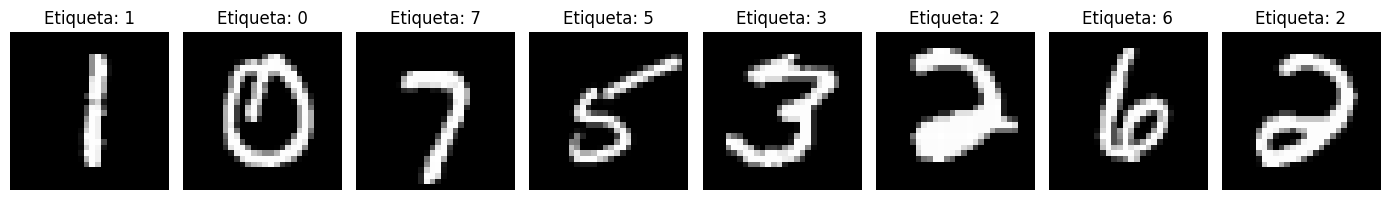

Etiqueta de la imagen 59 999: 8


In [ ]:
rng_visual = np.random.default_rng(SEED)
indices = rng_visual.choice(len(x_train_raw), size=8, replace=False)
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for ax, idx in zip(axes, indices):
    ax.imshow(x_train_raw[idx].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Etiqueta: {y_train_raw[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Etiqueta de la imagen 59 999:", y_train_raw[59999])


**Qué estás viendo:** una fila del arreglo guarda una imagen completa. `reshape`
cambia su forma, no aprende nada ni modifica los píxeles. La etiqueta viene del
dataset, no de la red. Aplanar conserva los valores, pero la FFNN no incorpora la
estructura espacial como lo haría una red convolucional (CNN).

**Ejercicio:** identifica dos imágenes difíciles incluso para una persona.
¿Una etiqueta correcta implica que el ejemplo sea fácil de clasificar?


## 3. Elegir la configuración y separar los datos

| Opción | Valor inicial | Decisión y alternativa |
|---|---:|---|
| `sample` | 1000 | Conserva el tamaño didáctico. Después prueba 5000. |
| `validation_size` | 1000 | Sale de los 60 000 originales y no se usa para actualizar pesos. |
| `hidden_size` | 100 | Conserva la arquitectura 784 → 100 → 10. |
| `epochs` | 100 | Cada época recorre todos los ejemplos seleccionados. |
| `batch_size` | 32 | Usa productos matriciales; `1` permite estudiar SGD por imagen. |
| `learning_rate` | 0.05 | Paso adaptado a gradientes **promediados por lote**. |
| `dropout_rate` | 0.5 | Probabilidad de apagar una activación durante entrenamiento. |
| `activation` | `relu` | También implementamos `leaky_relu`, `tanh`, `sigmoid`. |
| `loss` | `cuadratica` | Mantiene la idea original; también puedes usar `cross_entropy`. |

La tasa original era 0.005 con actualizaciones por imagen. Cambiar el lote altera
la cantidad y variabilidad de las actualizaciones: no esperamos el mismo resultado
al copiar esa tasa. Para explorar el régimen original usa `batch_size=1` y
`learning_rate=0.005`; las demás correcciones siguen vigentes.

**Entrenamiento** ajusta pesos; **validación** ayuda a comparar decisiones;
**prueba** mide el resultado final. No elegimos hiperparámetros mirando prueba
en cada época. Seleccionamos entrenamiento y validación al azar, sin solapamiento;
no hay balance exacto por clase, por eso mostramos su distribución.


In [ ]:
CONFIG = {
    "sample": 1000,
    "validation_size": 1000,
    "hidden_size": 100,
    "epochs": 100,
    "batch_size": 32,
    "learning_rate": 0.05,
    "dropout_rate": 0.5,
    "activation": "relu",       # relu | leaky_relu | tanh | sigmoid
    "loss": "cuadratica",       # cuadratica | cross_entropy
    "seed": SEED,
}
assert CONFIG["sample"] > 0 and CONFIG["validation_size"] > 0
assert CONFIG["sample"] + CONFIG["validation_size"] <= len(x_train_raw)
assert CONFIG["hidden_size"] > 0 and CONFIG["epochs"] > 0
assert CONFIG["batch_size"] > 0 and CONFIG["learning_rate"] > 0
assert 0 <= CONFIG["dropout_rate"] < 1
assert CONFIG["activation"] in {"relu", "leaky_relu", "tanh", "sigmoid"}
assert CONFIG["loss"] in {"cuadratica", "cross_entropy"}

permutacion = np.random.default_rng(CONFIG["seed"]).permutation(len(x_train_raw))
idx_train = permutacion[:CONFIG["sample"]]
idx_val = permutacion[CONFIG["sample"]:CONFIG["sample"] + CONFIG["validation_size"]]

# Convertimos ANTES de dividir: así controlamos la precisión y la memoria.
x_train = x_train_raw[idx_train].astype(np.float32) / 255.0
x_val = x_train_raw[idx_val].astype(np.float32) / 255.0
x_test = x_test_raw.astype(np.float32) / 255.0
y_train, y_val = y_train_raw[idx_train], y_train_raw[idx_val]

def one_hot(etiquetas, clases=10):
    return np.eye(clases, dtype=np.float32)[etiquetas]

t_train, t_val, t_test = one_hot(y_train), one_hot(y_val), one_hot(y_test)
assert not np.intersect1d(idx_train, idx_val).size
assert x_train.min() >= 0 and x_train.max() <= 1
assert np.all(t_train.sum(axis=1) == 1)
print("Formas: entrenamiento", x_train.shape, "validación", x_val.shape,
      "prueba", x_test.shape)
print("Píxeles normalizados:", x_train.dtype, "| One-hot:", t_train.dtype)
print("Conteo por dígito en entrenamiento:", np.bincount(y_train, minlength=10))
print("Etiqueta:", y_train[0], "→ one-hot:", t_train[0])


Formas: entrenamiento (1000, 784) validación (1000, 784) prueba (10000, 784)
Píxeles normalizados: float32 | One-hot: float32
Conteo por dígito en entrenamiento: [ 85  93  84 113  97  99 109 123  96 101]
Etiqueta: 5 → one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


**Qué aprender:** normalizar a [0, 1] controla la escala de las entradas; no convierte
una imagen en una probabilidad. One-hot representa una clase mediante un vector,
no establece un orden de similitud entre números: 9 no está «más lejos» de 0 que 1.

**Ejercicio:** escribe a mano el one-hot del dígito 3. ¿Qué cambia en las dimensiones
si trabajamos con imágenes de 32 × 32? ¿Y con tres canales de color?


## 4. Activaciones: por qué la red necesita una no linealidad

Sin activación, dos productos matriciales se reducen a uno:
$(XW_1)W_2 = X(W_1W_2)$. Agregar capas lineales no basta para aprender funciones
no lineales. La activación transforma la suma ponderada de cada neurona.

| Activación oculta | Función | Qué observar / limitación |
|---|---|---|
| ReLU | $\max(0,z)$ | Simple; gradiente 1 para positivos y 0 para negativos. Puede haber neuronas que no se activen. |
| Leaky ReLU | $z$ si $z>0$, $0.01z$ en otro caso | Conserva un gradiente pequeño para valores negativos. La pendiente es otra decisión. |
| tanh | $\tanh(z)$ | Salida entre −1 y 1, centrada en cero; se satura lejos de cero. |
| Sigmoide | $1/(1+e^{-z})$ | Salida entre 0 y 1; su derivada es como máximo 0.25 y se reduce al saturarse. |

En cero, ReLU no tiene una derivada única: adoptamos la convención de usar 0.
Derivamos respecto de la **preactivación `z`**, antes del dropout, para no perder
la información del signo. Para tanh y sigmoide importa la saturación:
una derivada pequeña transmite una señal pequeña a las capas anteriores.

**Otras alternativas:** ELU suaviza la región negativa; GELU y SiLU usan transiciones
suaves. Son extensiones posibles, pero requieren implementar su derivada al usar
backprop manual. Ninguna activación gana en todos los problemas.


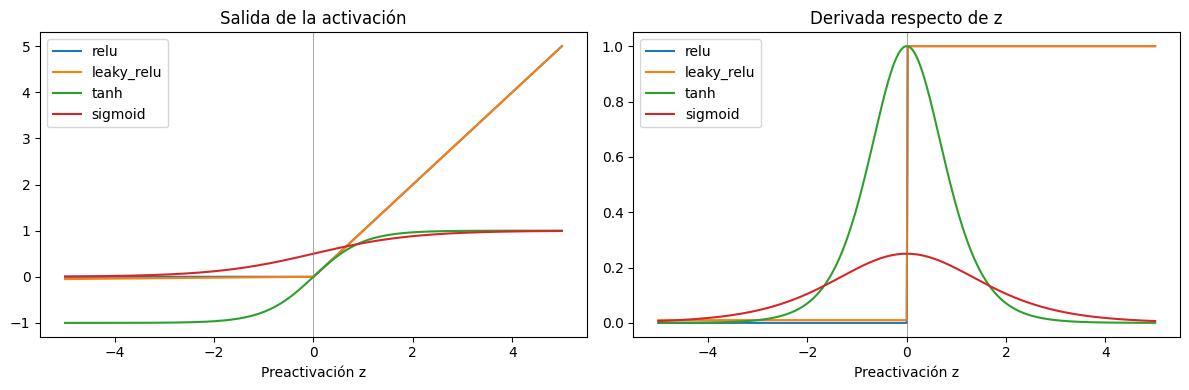

In [ ]:
def sigmoid(z):
    # Forma estable: solo evaluamos exponenciales de números no positivos.
    resultado = np.empty_like(z)
    positivos = z >= 0
    resultado[positivos] = 1 / (1 + np.exp(-z[positivos]))
    ez = np.exp(z[~positivos])
    resultado[~positivos] = ez / (1 + ez)
    return resultado

def activar(z, nombre):
    if nombre == "relu":
        return np.maximum(0, z)
    if nombre == "leaky_relu":
        return np.where(z > 0, z, 0.01 * z)
    if nombre == "tanh":
        return np.tanh(z)
    if nombre == "sigmoid":
        return sigmoid(z)
    raise ValueError(f"Activación desconocida: {nombre}")

def derivada_activacion(z, nombre):
    if nombre == "relu":
        return (z > 0).astype(z.dtype)
    if nombre == "leaky_relu":
        return np.where(z > 0, 1.0, 0.01).astype(z.dtype)
    if nombre == "tanh":
        return 1 - np.tanh(z) ** 2
    if nombre == "sigmoid":
        s = sigmoid(z)
        return s * (1 - s)
    raise ValueError(f"Activación desconocida: {nombre}")

z_demo = np.linspace(-5, 5, 501, dtype=np.float32)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre in ["relu", "leaky_relu", "tanh", "sigmoid"]:
    axes[0].plot(z_demo, activar(z_demo, nombre), label=nombre)
    axes[1].plot(z_demo, derivada_activacion(z_demo, nombre), label=nombre)
for ax, titulo in zip(axes, ["Salida de la activación", "Derivada respecto de z"]):
    ax.set_title(titulo)
    ax.set_xlabel("Preactivación z")
    ax.axvline(0, color="gray", lw=0.5)
    ax.legend()
plt.tight_layout()
plt.show()


## 5. Arquitectura, pesos y dropout

```text
X (B, 784) → Z = X @ W1 → H = activación(Z)
                       → H_drop = H * D → S = H_drop @ W2 (B, 10)
W1: (784, 100)                              W2: (100, 10)
```

`B` es el tamaño real del lote (el último puede ser menor).
Los **pesos** son parámetros aprendidos; tasa, épocas y tamaño de capa son
**hiperparámetros** elegidos antes del entrenamiento.
Con 100 neuronas tenemos $784\cdot100 + 100\cdot10 = 79\,400$ pesos.
Como el original, este modelo omite sesgos (*bias*). Agregarlos permitiría desplazar
las preactivaciones: $Z=XW_1+b_1$, $S=HW_2+b_2$; no son equivalentes a los pesos.

No inicializamos todos los pesos en cero: las neuronas deben empezar con valores
distintos para romper la simetría. Para ReLU usamos escala He $\sqrt{2/n_{in}}$
(ajustada a la pendiente para Leaky ReLU); para tanh/sigmoide, Xavier normal
$\sqrt{2/(n_{in}+n_{out})}$. Son heurísticas, no garantía de aprendizaje.
La salida lineal usa Xavier. Esto sustituye el uniforme fijo [−0.1, 0.1] del original.

En **dropout invertido**, $D=M/(1-p)$ con $M\sim\mathrm{Bernoulli}(1-p)$.
Para `p=0.5`, una activación retenida se multiplica por 2. Su valor esperado se
conserva; el gradiente también debe multiplicarse por el **mismo `D`**.
En validación, prueba e inferencia usamos `D=1`: no apagamos neuronas ni escalamos.


In [ ]:
def inicializar_modelo(config, entradas=784, clases=10, dtype=np.float32):
    rng = np.random.default_rng(config["seed"])
    h = config["hidden_size"]
    nombre = config["activation"]
    if nombre in {"relu", "leaky_relu"}:
        pendiente = 0.01 if nombre == "leaky_relu" else 0.0
        escala_1 = np.sqrt(2 / ((1 + pendiente ** 2) * entradas))
    else:
        escala_1 = np.sqrt(2 / (entradas + h))
    return {
        "W1": (rng.standard_normal((entradas, h)) * escala_1).astype(dtype),
        "W2": (rng.standard_normal((h, clases)) * np.sqrt(2 / (h + clases))).astype(dtype),
        "activation": nombre,
        "loss": config["loss"],
    }

def forward(x, modelo, dropout_rate=0.0, rng=None, escala_fija=None):
    z = x @ modelo["W1"]
    h = activar(z, modelo["activation"])
    if escala_fija is not None:
        d = escala_fija  # Permite comprobar gradientes con una máscara fija.
    elif dropout_rate > 0:
        if rng is None:
            raise ValueError("Entrenar con dropout requiere un generador aleatorio.")
        conservar = 1 - dropout_rate
        d = (rng.random(h.shape) < conservar).astype(h.dtype) / conservar
    else:
        d = np.ones_like(h)
    h_drop = h * d
    scores = h_drop @ modelo["W2"]
    return scores, (x, z, h_drop, d)

modelo_demo = inicializar_modelo(CONFIG)
scores_demo, cache_demo = forward(x_train[:4], modelo_demo)
print("Entrada:", x_train[:4].shape, "| W1:", modelo_demo["W1"].shape,
      "| W2:", modelo_demo["W2"].shape, "| Salida:", scores_demo.shape)
print("Pesos aprendibles:", modelo_demo["W1"].size + modelo_demo["W2"].size)


Entrada: (4, 784) | W1: (784, 100) | W2: (100, 10) | Salida: (4, 10)
Pesos aprendibles: 79400


## 6. Pérdida y retropropagación: qué estamos minimizando

El modo inicial utiliza **media de la semisuma de cuadrados por imagen**:

$$L=\frac{1}{2B}\sum_{i=1}^{B}\sum_{k=1}^{10}(S_{ik}-T_{ik})^2,
\qquad G_S=\frac{S-T}{B}.$$

El factor 1/2 simplifica la derivada. Esta pérdida es la mitad de la SSE media
por imagen del taller: **no** es el MSE promediado sobre los diez componentes.
Las puntuaciones lineales pueden ser negativas y no suman 1: no son probabilidades.
`argmax` selecciona la clase con puntuación mayor.

Para clasificación multiclase también implementamos **softmax + entropía cruzada**:

$$P_{ik}=\frac{e^{S_{ik}}}{\sum_j e^{S_{ij}}},\quad
L=-\frac1B\sum_{i,k}T_{ik}\log P_{ik},\quad G_S=\frac{P-T}{B}.$$

Restamos el máximo de cada fila antes de exponenciar para evitar desbordamientos;
calculamos log-softmax directamente para evitar `log(0)`. Softmax es una activación
de **salida**, no un reemplazo automático de ReLU en la capa oculta.
Sus probabilidades tampoco garantizan una confianza bien calibrada.

Aplicando la regla de la cadena:

$$G_{W_2}=H_{drop}^{T}G_S,\quad
G_Z=(G_SW_2^T)\odot D\odot f'(Z),\quad G_{W_1}=X^TG_Z.$$

Primero calculamos **ambos** gradientes con los pesos actuales; luego actualizamos
$W\leftarrow W-\alpha G_W$. Dividir por `B` hace que el paso use el gradiente medio.


In [ ]:
def log_softmax(scores):
    desplazadas = scores - scores.max(axis=1, keepdims=True)
    return desplazadas - np.log(np.exp(desplazadas).sum(axis=1, keepdims=True))

def perdida_y_delta(scores, targets, nombre):
    b = len(scores)
    if nombre == "cuadratica":
        residuo = scores - targets
        return float(0.5 * np.sum(residuo ** 2) / b), residuo / b
    if nombre == "cross_entropy":
        logp = log_softmax(scores)
        return float(-np.sum(targets * logp) / b), (np.exp(logp) - targets) / b
    raise ValueError(f"Pérdida desconocida: {nombre}")

def backward(delta_scores, cache, modelo):
    x, z, h_drop, d = cache
    grad_w2 = h_drop.T @ delta_scores
    # d incluye la máscara Y el factor 1/(1-p), también en el backward.
    delta_z = ((delta_scores @ modelo["W2"].T) * d
               * derivada_activacion(z, modelo["activation"]))
    grad_w1 = x.T @ delta_z
    return {"W1": grad_w1, "W2": grad_w2}


### Comprobar que los gradientes corresponden a la pérdida

En una red pequeña de práctica comparamos backprop con diferencias finitas:
$\partial L/\partial w\approx[L(w+\epsilon)-L(w-\epsilon)]/(2\epsilon)$.
Usamos `float64` y **la misma máscara de dropout** en ambas evaluaciones;
si la sorteáramos otra vez, compararíamos dos funciones distintas.
Esta comprobación recorre las cuatro activaciones y las dos pérdidas.
No entrena ni modifica el modelo principal.


In [ ]:
def comprobar_gradientes():
    rng = np.random.default_rng(23)
    x = rng.normal(size=(4, 5))
    targets = np.eye(3)[[0, 1, 2, 1]]
    d = (rng.random((4, 4)) > 0.5).astype(np.float64) * 2
    errores = []
    eps = 1e-6
    for activacion in ["relu", "leaky_relu", "tanh", "sigmoid"]:
        for perdida in ["cuadratica", "cross_entropy"]:
            cfg = dict(CONFIG, hidden_size=4, activation=activacion, loss=perdida)
            m = inicializar_modelo(cfg, entradas=5, clases=3, dtype=np.float64)
            scores, cache = forward(x, m, escala_fija=d)
            _, delta = perdida_y_delta(scores, targets, perdida)
            grads = backward(delta, cache, m)
            for nombre in ["W1", "W2"]:
                for idx in np.ndindex(m[nombre].shape):
                    original = m[nombre][idx]
                    m[nombre][idx] = original + eps
                    lp, _ = perdida_y_delta(forward(x, m, escala_fija=d)[0], targets, perdida)
                    m[nombre][idx] = original - eps
                    lm, _ = perdida_y_delta(forward(x, m, escala_fija=d)[0], targets, perdida)
                    m[nombre][idx] = original
                    numerico = (lp - lm) / (2 * eps)
                    analitico = grads[nombre][idx]
                    errores.append(abs(numerico - analitico) / max(1.0, abs(numerico), abs(analitico)))
    assert max(errores) < 1e-6, f"Gradientes inconsistentes: {max(errores):.2e}"
    print(f"Gradientes verificados: error máximo normalizado = {max(errores):.2e}")

comprobar_gradientes()


Gradientes verificados: error máximo normalizado = 5.73e-10


## 7. Entrenar y registrar métricas comparables

Barajamos los ejemplos en cada época y actualizamos por minilotes. Al finalizar
cada época medimos entrenamiento y validación **sin dropout y con los mismos
pesos finales**. Así las curvas sí son comparables: el original acumulaba aciertos
durante el entrenamiento, con dropout y pesos que iban cambiando.

Seguimos 100 épocas por defecto, sin selección automática de la mejor época.
Observa validación para proponer un número de épocas o parada temprana en otro
experimento. No se toca prueba durante este bucle.


In [ ]:
def evaluar(x, targets, modelo, batch_size=512):
    suma_loss, aciertos = 0.0, 0
    for inicio in range(0, len(x), batch_size):
        xb, tb = x[inicio:inicio + batch_size], targets[inicio:inicio + batch_size]
        scores, _ = forward(xb, modelo)  # Sin dropout.
        loss, _ = perdida_y_delta(scores, tb, modelo["loss"])
        suma_loss += loss * len(xb)  # Ponderar evita sesgo por el último lote.
        aciertos += int(np.sum(scores.argmax(axis=1) == tb.argmax(axis=1)))
    return suma_loss / len(x), aciertos / len(x)

def entrenar(config, verbose=True):
    modelo = inicializar_modelo(config)
    rng = np.random.default_rng(config["seed"] + 1)
    historia = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    inicio_tiempo = time.perf_counter()
    for epoca in range(1, config["epochs"] + 1):
        orden = rng.permutation(len(x_train))
        for inicio in range(0, len(orden), config["batch_size"]):
            idx = orden[inicio:inicio + config["batch_size"]]
            scores, cache = forward(x_train[idx], modelo, config["dropout_rate"], rng)
            loss, delta = perdida_y_delta(scores, t_train[idx], modelo["loss"])
            if not np.isfinite(loss):
                raise FloatingPointError("Pérdida no finita: reduce learning_rate y reinicia el entrenamiento.")
            gradientes = backward(delta, cache, modelo)
            for nombre in ["W1", "W2"]:
                modelo[nombre] -= config["learning_rate"] * gradientes[nombre]
        train_loss, train_acc = evaluar(x_train, t_train, modelo)
        val_loss, val_acc = evaluar(x_val, t_val, modelo)
        for clave, valor in zip(historia, [train_loss, val_loss, train_acc, val_acc]):
            historia[clave].append(valor)
        if verbose and (epoca == 1 or epoca % 10 == 0 or epoca == config["epochs"]):
            print(f"Época {epoca:3d}/{config['epochs']} | loss: {train_loss:.4f} / {val_loss:.4f}"
                  f" | accuracy entrenamiento/validación: {train_acc:.1%} / {val_acc:.1%}")
    if verbose:
        print(f"Tiempo de entrenamiento: {time.perf_counter() - inicio_tiempo:.1f} s")
    return modelo, historia

modelo, historia = entrenar(CONFIG)
assert all(np.isfinite(v).all() for v in historia.values())


Época   1/100 | loss: 0.4291 / 0.4330 | accuracy entrenamiento/validación: 37.0% / 35.5%
Época  10/100 | loss: 0.2248 / 0.2502 | accuracy entrenamiento/validación: 86.1% / 78.5%
Época  20/100 | loss: 0.1645 / 0.1995 | accuracy entrenamiento/validación: 92.6% / 84.3%
Época  30/100 | loss: 0.1227 / 0.1699 | accuracy entrenamiento/validación: 94.4% / 84.6%
Época  40/100 | loss: 0.1088 / 0.1636 | accuracy entrenamiento/validación: 95.7% / 86.0%
Época  50/100 | loss: 0.1006 / 0.1631 | accuracy entrenamiento/validación: 97.2% / 85.8%
Época  60/100 | loss: 0.0904 / 0.1540 | accuracy entrenamiento/validación: 97.3% / 86.5%
Época  70/100 | loss: 0.0802 / 0.1510 | accuracy entrenamiento/validación: 98.0% / 85.6%
Época  80/100 | loss: 0.0766 / 0.1507 | accuracy entrenamiento/validación: 98.1% / 86.1%
Época  90/100 | loss: 0.0747 / 0.1492 | accuracy entrenamiento/validación: 98.0% / 86.8%
Época 100/100 | loss: 0.0704 / 0.1494 | accuracy entrenamiento/validación: 98.4% / 86.8%
Tiempo de entrenamien

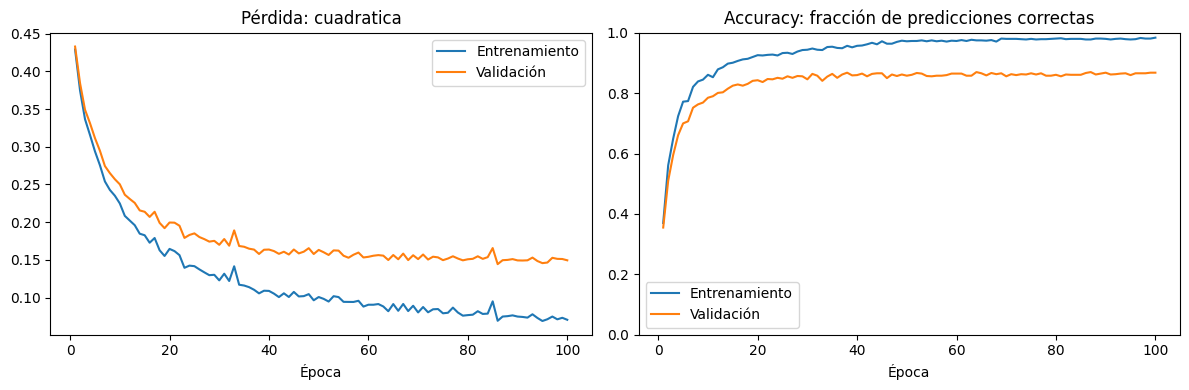

In [ ]:
epocas = np.arange(1, CONFIG["epochs"] + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epocas, historia["train_loss"], label="Entrenamiento")
axes[0].plot(epocas, historia["val_loss"], label="Validación")
axes[0].set_title(f"Pérdida: {modelo['loss']}")
axes[1].plot(epocas, historia["train_acc"], label="Entrenamiento")
axes[1].plot(epocas, historia["val_acc"], label="Validación")
axes[1].set_title("Accuracy: fracción de predicciones correctas")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
plt.tight_layout()
plt.show()


### Leer las curvas sin inventar conclusiones

- Si entrenamiento mejora mientras validación empeora, puede haber sobreajuste.
- Si ambos resultados son bajos, investiga capacidad, datos, tasa o tiempo de entrenamiento.
- Una pérdida menor no garantiza una mayor accuracy: una mide distancias o
  probabilidades y la otra solo si el máximo corresponde a la clase correcta.
- Un estancamiento no demuestra que la pérdida cuadrática sea la única causa.
  Tampoco una brecha pequeña demuestra por sí sola que dropout «funcionó».
  Para estudiar su efecto, compara con `dropout_rate=0` bajo condiciones iguales.
- No compares directamente el valor de pérdida cuadrática y entropía cruzada:
  tienen definiciones y escalas distintas.

**Ejercicio:** anota una observación respaldada por tus curvas, una hipótesis para
explicarla y un experimento que pueda comprobarla. Distingue esas tres cosas.


## 8. Evaluación final y errores de clasificación

Usamos las 10 000 imágenes de prueba. La matriz de confusión tiene etiquetas
**reales en filas** y **predicciones en columnas**. La diagonal representa aciertos.
Accuracy resume el conjunto; mirar errores por clase aporta información adicional.

Después de explorar prueba, no la uses para elegir el mejor experimento y presentar
su resultado como una evaluación independiente. En comparaciones usa validación.


Prueba final | pérdida (cuadratica): 0.1387 | accuracy: 88.98%


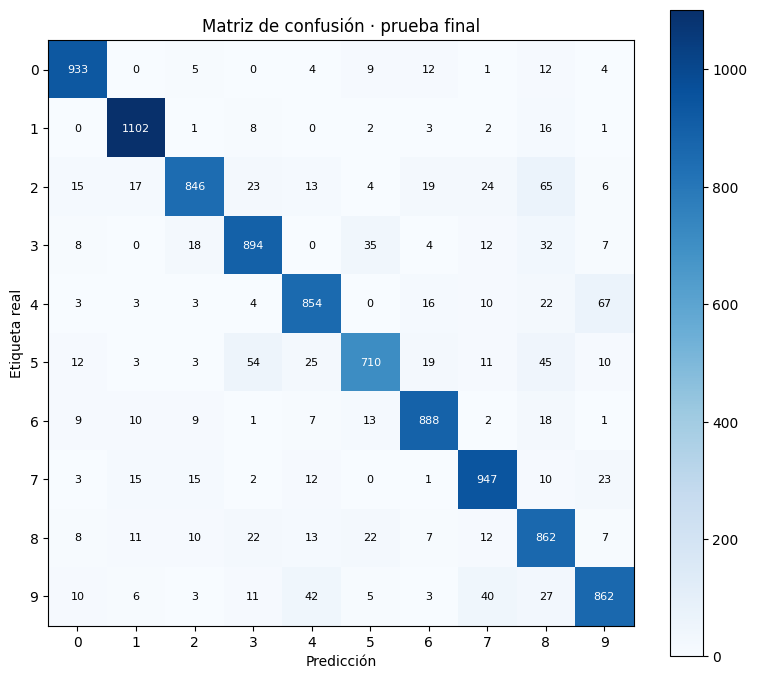

Accuracy por dígito: [0.952 0.971 0.82  0.885 0.87  0.796 0.927 0.921 0.885 0.854]


In [ ]:
test_loss, test_acc = evaluar(x_test, t_test, modelo)
print(f"Prueba final | pérdida ({modelo['loss']}): {test_loss:.4f} | accuracy: {test_acc:.2%}")

def predecir_lote(x, modelo, batch_size=512):
    return np.concatenate([forward(x[i:i + batch_size], modelo)[0]
                           for i in range(0, len(x), batch_size)])

test_scores = predecir_lote(x_test, modelo)
test_pred = test_scores.argmax(axis=1)
assert np.isclose(test_acc, np.mean(test_pred == y_test))
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test, test_pred), 1)
assert confusion.sum() == len(y_test)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion, cmap="Blues")
for fila in range(10):
    for col in range(10):
        ax.text(col, fila, str(confusion[fila, col]), ha="center", va="center",
                color="white" if confusion[fila, col] > confusion.max() / 2 else "black", fontsize=8)
ax.set(xticks=range(10), yticks=range(10), xlabel="Predicción", ylabel="Etiqueta real",
       title="Matriz de confusión · prueba final")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()
print("Accuracy por dígito:", np.round(confusion.diagonal() / confusion.sum(axis=1), 3))


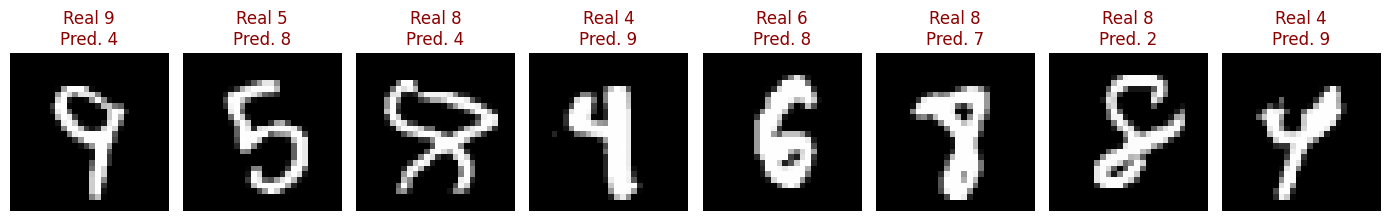

In [ ]:
errores = np.flatnonzero(test_pred != y_test)
if len(errores):
    elegidos = np.random.default_rng(SEED).choice(errores, size=min(8, len(errores)), replace=False)
    fig, axes = plt.subplots(1, len(elegidos), figsize=(14, 2.5), squeeze=False)
    for ax, idx in zip(axes.ravel(), elegidos):
        ax.imshow(x_test[idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Real {y_test[idx]}\nPred. {test_pred[idx]}", color="darkred")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No hay errores en este conjunto de prueba.")


## 9. Inferencia: observar la imagen y sus diez salidas

Inferencia es una pasada hacia adelante con pesos ya aprendidos, sin backprop ni
dropout. Puedes cambiar `indice_imagen` entre 0 y 9999.
No presentes el mayor score cuadrático como «porcentaje de confianza».
En modo entropía cruzada sí mostramos softmax, como probabilidades del modelo.


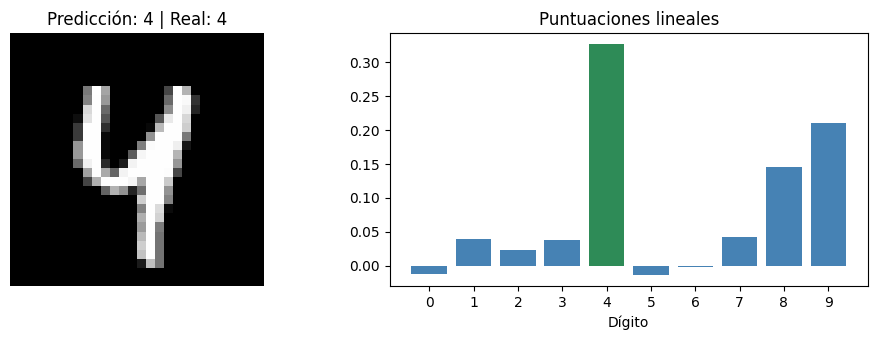

Salidas: [-0.012  0.039  0.023  0.038  0.326 -0.013 -0.002  0.042  0.145  0.211]


In [ ]:
def predecir_digito(vector_784, modelo=modelo):
    vector = np.asarray(vector_784, dtype=np.float32)
    if vector.shape != (784,) or not np.isfinite(vector).all():
        raise ValueError("Se espera un vector finito de exactamente 784 píxeles.")
    if vector.min() < 0 or vector.max() > 1:
        raise ValueError("Normaliza los píxeles a [0, 1] antes de predecir.")
    scores, _ = forward(vector[None, :], modelo)
    salidas = np.exp(log_softmax(scores))[0] if modelo["loss"] == "cross_entropy" else scores[0]
    return int(scores.argmax(axis=1)[0]), salidas

indice_imagen = 42
assert 0 <= indice_imagen < len(x_test)
prediccion, salidas = predecir_digito(x_test[indice_imagen])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(x_test[indice_imagen].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Predicción: {prediccion} | Real: {y_test[indice_imagen]}")
axes[0].axis("off")
axes[1].bar(range(10), salidas, color=["seagreen" if k == prediccion else "steelblue" for k in range(10)])
axes[1].set_xticks(range(10))
axes[1].set_title("Probabilidades softmax" if modelo["loss"] == "cross_entropy" else "Puntuaciones lineales")
axes[1].set_xlabel("Dígito")
plt.tight_layout()
plt.show()
print("Salidas:", np.round(salidas, 3))


## 10. Imagen propia · opcional

Activa `SUBIR_IMAGEN` y ejecuta esta celda en Colab. Sube un PNG/JPG con **un solo
dígito**, trazo claro, fondo uniforme y margen alrededor. No uses una hoja completa.
`FONDO_BLANCO=True` indica trazo oscuro sobre fondo claro; cambia a `False` si tu
imagen ya tiene fondo negro. No invertimos siempre, como hacía el taller original.

El preprocesamiento convierte a gris, recorta el trazo, conserva su proporción,
lo coloca en un lienzo 28 × 28 y lo normaliza. Muestra el resultado que la red recibe.
Es una aproximación: no reproduce exactamente el centrado por centro de masa de
MNIST. Una foto puede tener sombras, ruido o un estilo distinto a los datos de
entrenamiento; un error aquí también puede venir de ese cambio de distribución.


In [ ]:
def preparar_imagen_propia(imagen, fondo_blanco=True):
    imagen = ImageOps.exif_transpose(imagen).convert("RGBA")
    fondo = Image.new("RGBA", imagen.size, "white" if fondo_blanco else "black")
    imagen = Image.alpha_composite(fondo, imagen).convert("L")
    if fondo_blanco:
        imagen = ImageOps.invert(imagen)
    imagen = ImageOps.autocontrast(imagen)
    pixeles = np.asarray(imagen)
    yy, xx = np.where(pixeles > 40)  # Umbral heurístico para ubicar el trazo.
    if len(xx) == 0:
        raise ValueError("No se detectó un trazo. Revisa el contraste y el color del fondo.")
    recorte = imagen.crop((int(xx.min()), int(yy.min()), int(xx.max()) + 1, int(yy.max()) + 1))
    recorte.thumbnail((20, 20), Image.Resampling.LANCZOS)
    lienzo = Image.new("L", (28, 28), 0)
    lienzo.paste(recorte, ((28 - recorte.width) // 2, (28 - recorte.height) // 2))
    vector = np.asarray(lienzo, dtype=np.float32).reshape(784) / 255.0
    return vector, lienzo

SUBIR_IMAGEN = False
FONDO_BLANCO = True
if SUBIR_IMAGEN:
    from google.colab import files
    import io
    subidos = files.upload()
    for nombre, contenido in subidos.items():
        original = Image.open(io.BytesIO(contenido))
        vector, preparada = preparar_imagen_propia(original, FONDO_BLANCO)
        pred, valores = predecir_digito(vector)
        fig, axes = plt.subplots(1, 2, figsize=(7, 3))
        axes[0].imshow(original)
        axes[0].set_title("Imagen original")
        axes[1].imshow(preparada, cmap="gray", vmin=0, vmax=255)
        axes[1].set_title(f"Entrada 28 × 28 | Predicción: {pred}")
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()
        print(nombre, "→", pred, "| salidas:", np.round(valores, 3))
else:
    print("Carga opcional desactivada. Cambia SUBIR_IMAGEN a True para probar tu dibujo.")


Carga opcional desactivada. Cambia SUBIR_IMAGEN a True para probar tu dibujo.


## 11. Laboratorio de activaciones · opcional

Activa el siguiente experimento para entrenar cuatro redes nuevas durante 30 épocas.
El modelo principal se conserva. Usamos las mismas muestras, semilla, lotes y pérdida;
la escala de inicialización se adapta a cada familia de activaciones.
Por eso comparamos **configuraciones completas**, no aislamos perfectamente el efecto
de la función. La tasa fija puede favorecer una activación: ajustarla solo con
validación y repetir varias semillas sería una comparación más sólida.

No evaluamos estas redes en prueba. Una sola semilla y 1000 ejemplos no permiten
declarar una activación universalmente mejor.


In [ ]:
COMPARAR_ACTIVACIONES = False
if COMPARAR_ACTIVACIONES:
    resultados_activaciones = []
    for nombre in ["relu", "leaky_relu", "tanh", "sigmoid"]:
        cfg = dict(CONFIG, activation=nombre, epochs=30)
        candidato, curvas = entrenar(cfg, verbose=False)
        loss_val, acc_val = evaluar(x_val, t_val, candidato)
        resultados_activaciones.append((nombre, loss_val, acc_val))
        print(f"{nombre:12s} | pérdida validación: {loss_val:.4f} | accuracy: {acc_val:.2%}")
    plt.bar([r[0] for r in resultados_activaciones], [r[2] for r in resultados_activaciones])
    plt.ylim(0, 1)
    plt.ylabel("Accuracy de validación")
    plt.title("Comparación exploratoria · 30 épocas por activación")
    plt.show()
else:
    print("Comparación opcional desactivada.")


Comparación opcional desactivada.


## 12. Guardar los pesos y recuperar una predicción

Guardamos pesos, activación, pérdida y configuración en un archivo `.npz`.
Se guarda en cada ejecución; activa `DESCARGAR_MODELO` para descargarlo desde Colab.
La comprobación vuelve a cargar el archivo y verifica que reproduce las salidas.
Puedes subirlo en otra sesión y usar la función `cargar_modelo` tras ejecutar las
definiciones de activación, forward y predicción, sin volver a entrenar.

Esto guarda un modelo para **inferencia**. No guarda el estado del generador ni
el progreso del entrenamiento para reanudarlo exactamente.


In [ ]:
RUTA_MODELO = Path("ffnn_mnist_numpy.npz")
np.savez_compressed(RUTA_MODELO, W1=modelo["W1"], W2=modelo["W2"],
                    activation=np.array(modelo["activation"]), loss=np.array(modelo["loss"]),
                    config_json=np.array(json.dumps(CONFIG)))

def cargar_modelo(ruta):
    with np.load(ruta, allow_pickle=False) as datos:
        cargado = {"W1": datos["W1"].copy(), "W2": datos["W2"].copy(),
                   "activation": str(datos["activation"].item()),
                   "loss": str(datos["loss"].item())}
    assert cargado["W1"].shape[0] == 784
    assert cargado["W1"].shape[1] == cargado["W2"].shape[0]
    assert cargado["W2"].shape[1] == 10
    return cargado

modelo_recuperado = cargar_modelo(RUTA_MODELO)
np.testing.assert_allclose(forward(x_test[:5], modelo)[0],
                           forward(x_test[:5], modelo_recuperado)[0])
print("Modelo guardado y verificado:", RUTA_MODELO.resolve())
DESCARGAR_MODELO = False
if DESCARGAR_MODELO:
    from google.colab import files
    files.download(str(RUTA_MODELO))


Modelo guardado y verificado: ffnn_mnist_numpy.npz


## 13. Ejercicios para entregar

1. **Sigue las dimensiones.** Con un lote de 32 y 100 neuronas ocultas, escribe
   las formas de `X`, `W1`, `Z`, `H_drop`, `W2`, `scores`, `grad_w1` y `grad_w2`.
2. **Calcula una activación.** Para `z = [-2, 0, 3]`, calcula ReLU y Leaky ReLU,
   junto con sus derivadas según las convenciones del notebook. Comprueba con código.
3. **Comprende dropout.** Para `h=[2,4,6,8]`, `M=[1,0,1,0]` y `p=0.5`, calcula
   `h_drop`. Explica por qué el backward también multiplica por 2 donde `M=1`.
4. **Compara datos y capacidad.** Cambia únicamente `sample` de 1000 a 5000.
   Registra tiempo y accuracy de validación. Luego restaura `sample` y prueba
   `hidden_size=20`. Explica qué decisión cambia en cada experimento.
5. **Investiga regularización.** Compara `dropout_rate=0` y `0.5`. Usa al menos
   tres semillas y la misma división de datos dentro de cada comparación.
   ¿Las diferencias se mantienen? No justifiques el efecto con una sola curva.
6. **Prueba otra pérdida.** Cambia únicamente `loss` a `cross_entropy` para una
   primera comparación. Explica qué representan las salidas y compara accuracy
   de validación, no los valores absolutos de pérdidas diferentes.
7. **Analiza un error.** Selecciona un fallo de la matriz de confusión y describe
   una posible ambigüedad visual. No asumas que una neurona «entiende» el número.
8. **Dibuja tres dígitos.** Muestra el original, la entrada transformada y la
   predicción. ¿Se ve el trazo completo? ¿Cambió su proporción?

Registra cada experimento antes de ejecutarlo:

| Cambio | Semilla | Épocas | Loss usada | Accuracy validación | Tiempo | Observación |
|---|---|---|---|---|---|---|
| Base | | | | | | |

### Pistas para revisar tus cálculos

- Ejercicio 1: `(32,784)`, `(784,100)`, `(32,100)`, `(32,100)`, `(100,10)`,
  `(32,10)`, `(784,100)`, `(100,10)`.
- Ejercicio 2: ReLU `[0,0,3]`, derivada `[0,0,1]`; Leaky ReLU
  `[-0.02,0,3]`, derivada `[0.01,0.01,1]`.
- Ejercicio 3: `[4,0,12,0]`. La derivada de multiplicar por una constante es
  esa misma constante.

### Preguntas de cierre

¿Qué aprende la red? Pesos que ayudan a separar las diez clases a partir de ejemplos
etiquetados. ¿Cómo decide? Elige la clase cuya salida es mayor. ¿Quién calcula
los gradientes? Aquí los programamos manualmente con la regla de la cadena;
NumPy no realiza diferenciación automática. ¿Por qué es feedforward si hay
backprop? Feedforward describe el flujo de la arquitectura sin conexiones
recurrentes; backprop es el procedimiento para calcular gradientes al entrenarla.


## 14. Si aparece un error

| Síntoma | Acción concreta |
|---|---|
| `NameError` | Ejecuta las celdas anteriores: las variables viven en la sesión, no en el archivo. |
| Descarga falla / timeout | Revisa la conexión y vuelve a ejecutar la descarga. Los archivos se verifican antes de reutilizarse. |
| `nan`, `inf` o pérdida creciente | Reduce `learning_rate`, reinicia desde la configuración y observa las primeras épocas. |
| Cambié la activación pero las curvas no cambian | Vuelve a ejecutar configuración y entrenamiento: editar texto no recalcula resultados. |
| La imagen propia se predice mal | Mira el lienzo 28 × 28, revisa fondo, contraste, recorte y estilo del trazo. |
| No tengo `google.colab` localmente | Mantén las opciones de subida/descarga en `False`; el recorrido principal también funciona en Jupyter. |
| El entorno se desconectó | Ejecuta de nuevo las celdas. Recupera los pesos de tu `.npz` si los descargaste. |

## Qué cambió respecto al taller recibido

Se conserva la FFNN desde cero. Se corrigen la derivada de ReLU (usa `z>0`),
el factor del gradiente de dropout y las curvas (cada conjunto utiliza sus propias
métricas). Se define la pérdida cuadrática sin confundir SSE y MSE, se evita
interpretar scores como probabilidades y se sustituyen conclusiones fijas por
preguntas que se responden con los resultados de cada ejecución.
Se agregan validación, minilotes, mezcla por época, inicialización por escala,
activaciones intercambiables, comprobación de gradientes, entropía cruzada opcional,
matriz de confusión, carga de imágenes y exportación para Colab.
Por esos cambios, los resultados no tienen por qué reproducir los porcentajes del original.

## Referencias para continuar

- [FAQ oficial de Colab](https://research.google.com/colaboratory/faq.html):
  importar notebooks, entorno temporal y elección de acelerador.
- [Implementación de MNIST en torchvision](https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py):
  archivos originales, espejo y sumas de verificación.
- [Dropout invertido](https://docs.pytorch.org/docs/2.14/generated/torch.nn.modules.dropout.Dropout.html):
  escala durante entrenamiento y comportamiento en evaluación.
- [Inicialización He, artículo original](https://arxiv.org/abs/1502.01852)
  y [Xavier, artículo original](https://proceedings.mlr.press/v9/glorot10a.html).
- [Dropout, artículo original](https://jmlr.org/papers/v15/srivastava14a.html).

Las referencias a PyTorch documentan conceptos y el origen de los archivos;
el modelo de este notebook se implementa exclusivamente con NumPy.
